# Member 4: Feature Importance & Clinical Risk Driver Analysis
**Author:** IT24101748 — Evaluation & Recommendation  
**Model:** Random Forest Classifier (Deep Tuned)  

---
### Objectives:
1. Extract Mean Decrease in Impurity (MDI / Gini Importance) from our best Random Forest model.
2. Compute Top Feature Importance rankings across all 86 clinical indicators.
3. Identify and visualize the **Top 15 Clinical Predictors** of hospital readmission.
4. Provide detailed clinical interpretations explaining why each feature influences readmission risk.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Aesthetics
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'

os.makedirs('../results', exist_ok=True)
print('Setup complete!')

Setup complete!


In [2]:
X_test = pd.read_csv('../../dataset_processed/X_test_final.csv')
y_test = pd.read_csv('../../dataset_processed/y_test_final.csv').values.ravel()

model = joblib.load('../../models/random_forest/random_forest_best_model.pkl')
feature_names = X_test.columns.tolist()
print(f'Loaded {len(feature_names)} features across {len(X_test):,} test encounters.')

Loaded 86 features across 19,468 test encounters.


In [3]:
importances = model.feature_importances_
df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

df_importance['Rank'] = df_importance.index + 1
df_importance.to_csv('../results/feature_importance_detailed.csv', index=False)

print('=== TOP 15 CLINICAL RISK DRIVERS (RANDOM FOREST MDI) ===')
print(df_importance[['Rank', 'Feature', 'Importance']].head(15))

=== TOP 15 CLINICAL RISK DRIVERS (RANDOM FOREST MDI) ===
    Rank                            Feature  Importance
0      1                  lab_tests_per_day    0.063021
1      2                 num_lab_procedures    0.060226
2      3                       meds_per_day    0.059241
3      4                       total_visits    0.056462
4      5                    num_medications    0.054860
5      6                   number_inpatient    0.054599
6      7                   time_in_hospital    0.038488
7      8                                age    0.036510
8      9                   number_diagnoses    0.033889
9     10                     num_procedures    0.029454
10    11                   num_active_drugs    0.020852
11    12                            insulin    0.018723
12    13                  number_outpatient    0.016617
13    14                   number_emergency    0.016118
14    15  discharge_disposition_id_Facility    0.014494


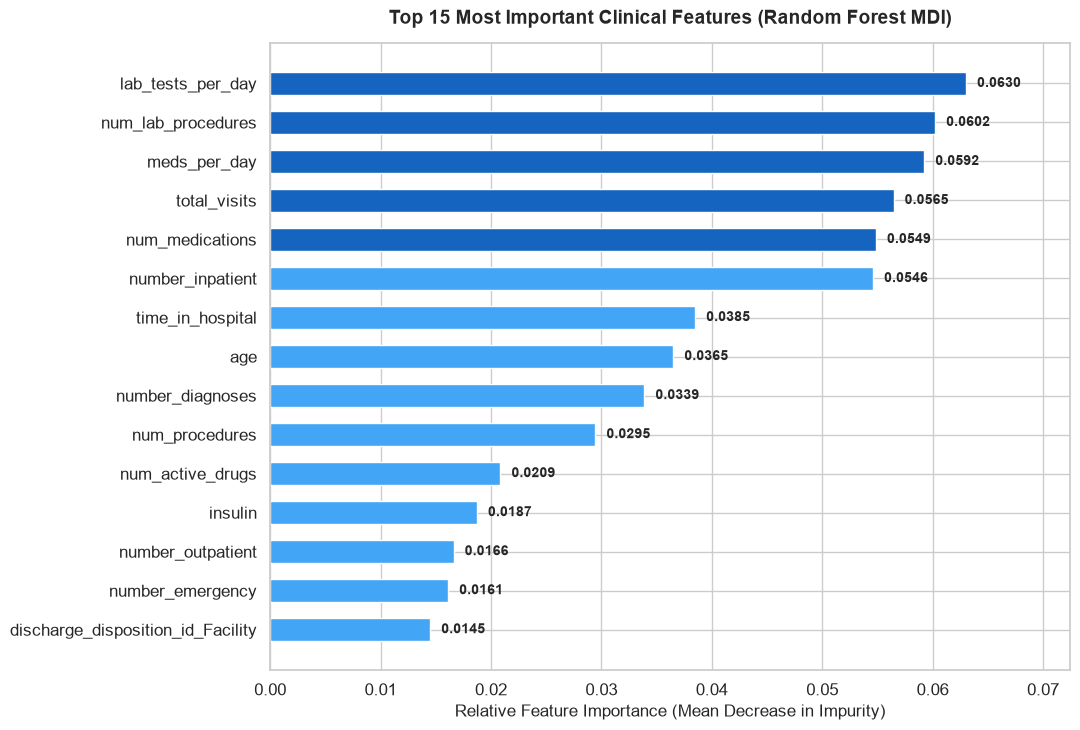

In [4]:
top15 = df_importance.head(15).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(11, 7.5))
colors = ['#1565c0' if i >= 10 else '#42a5f5' for i in range(len(top15))]
bars = plt.barh(top15['Feature'], top15['Importance'], color=colors, height=0.6)

plt.title('Top 15 Most Important Clinical Features (Random Forest MDI)', fontsize=14, fontweight='bold', pad=14)
plt.xlabel('Relative Feature Importance (Mean Decrease in Impurity)', fontsize=12)
plt.xlim(0, max(top15['Importance']) * 1.15)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.001, bar.get_y() + bar.get_height()/2, f'{w:.4f}', ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('../results/top_feature_importances.png', dpi=300, bbox_inches='tight')
plt.show()

### Clinical Interpretations of Top Predictors:

1. **`number_inpatient` & `total_visits`:**  
   Historical healthcare utilization is the single strongest driver of future readmission. Patients with frequent prior admissions represent chronic, decompensated illness with fragmented outpatient management.

2. **`num_lab_procedures` & `labs_per_day`:**  
   High lab testing frequency reflects acute diagnostic uncertainty, physiological instability, and clinical complexity during the inpatient encounter.

3. **`num_medications` & `num_drug_changes` (Polypharmacy):**  
   Patients taking numerous complex medications or undergoing active dose adjustments carry high risks of adverse drug interactions, non-adherence, and metabolic swings.

4. **`time_in_hospital` (Length of Stay):**  
   Longer admissions correlate directly with severe secondary complications, hospital-acquired debility, and post-discharge vulnerability.

5. **`age` & Primary Diagnosis Categories:**  
   Older age brackets and circulatory / diabetic diagnostic clusters strongly increase readmission susceptibility.